# From parabolic equations to backward stochastic representations

A semilinear parabolic equation can be written as:

$$
\partial_t u(t,x)+\mu(t,x)^{\mathsf T}\nabla_x u(t,x)+\frac12\operatorname{tr}\!\left(\sigma(t,x)\sigma(t,x)^{\mathsf T}\nabla_x^2u(t,x)\right)+f\!\left(t,x,u(t,x),\sigma(t,x)^{\mathsf T}\nabla_xu(t,x)\right)=0,
\qquad u(T,x)=g(x).
$$

Here, $t\in[0,T]$ is time; $x\in\mathbb R^d$ is the state; $u(t,x)$ is the unknown value; $\mu(t,x)$ is the drift; $\sigma(t,x)$ is the diffusion matrix; $\nabla_xu$ and $\nabla_x^2u$ are the gradient and Hessian; $f$ is the driver; $g$ is the terminal value; $d$ is the state dimension; and $\operatorname{tr}$ is the matrix trace.

In [1]:
using RiskLabAI,Random,Statistics,LinearAlgebra,DataFrames,Dates,Plots,CSV,TOML
using RiskLabAI.Pde: FBSDESolver,FBSNNSolver,solve_pde
Base.set_zero_subnormals(false)
BLAS.set_num_threads(1)
include(joinpath("..","support","BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
include(joinpath("..","support","BookPDEStudy.jl"))
using .BookPDEStudy
@assert pkgversion(RiskLabAI)==v"1.1.0"
configure_plots!()
default(left_margin=11Plots.mm,bottom_margin=8Plots.mm)
paths=output_paths("29_deep_bsde")
method_colors=Dict("DTNN"=>palette.green,"DeepBSDE"=>palette.cyan,"FBSNN"=>palette.rose)
family_labels=Dict("default"=>"Default risk","quadratic"=>"Quadratic fixed-volatility value","maxmin"=>"Maximum-minus-minimum value","basket"=>"Basket value","best"=>"Best-of value","different"=>"Different borrowing and lending rates","hjb"=>"Hamilton-Jacobi-Bellman")
finite_sequence(values)=!isempty(values)&&all(isfinite,values)
BookSupport._number(::Missing,digits)="Not available"
function table(frame,name,caption)
    shown=copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column]=ifelse.(shown[!,column],"Yes","No")
        elseif eltype(shown[!,column])<:AbstractFloat
            shown[!,column]=[isfinite(value) ? value : missing for value in shown[!,column]]
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter29-"*replace(name,"_"=>"-"))
end
function history_summary(histories,reference=NaN)
    rows=NamedTuple[]
    for method in sort(unique([item.method for item in histories]))
        selected=filter(item->item.method==method,histories)
        values=[item.estimates[end] for item in selected]
        losses=[item.losses[end] for item in selected]
        push!(rows,(Method=method,Runs=length(selected),initial=mean(values),initial_std=length(values)>1 ? std(values) : 0.0,loss=mean(losses),loss_std=length(losses)>1 ? std(losses) : 0.0,seconds=mean(item.seconds for item in selected),parameters=first(selected).parameters,error=isfinite(reference) ? abs(mean(values)-reference) : NaN,relative=isfinite(reference) ? abs(mean(values)-reference)/max(abs(reference),1e-12) : NaN))
    end
    frame=DataFrame(rows)
    rename!(frame,["Method","Runs","Initial value mean","Initial value standard deviation","Final loss mean","Final loss standard deviation","Mean run time seconds","Parameters","Absolute error","Relative error"])
    return frame
end
function plot_histories(histories,reference,stem,title)
    panels=[plot(;xlabel="Training round",ylabel="Initial value estimate",title,legend=:outertop),plot(;xlabel="Training round",ylabel="Terminal loss",title="Validation loss",yscale=:log10,legend=:outertop)]
    for method in ("DTNN","DeepBSDE","FBSNN")
        selected=filter(item->item.method==method,histories)
        isempty(selected)&&continue
        estimates=reduce(hcat,[item.estimates for item in selected])
        losses=reduce(hcat,[item.losses for item in selected])
        center=vec(mean(estimates;dims=2)); spread=vec(std(estimates;dims=2,corrected=false))
        loss_center=vec(mean(losses;dims=2)); loss_spread=vec(std(losses;dims=2,corrected=false))
        rounds=1:length(center)
        plot!(panels[1],rounds,center;ribbon=spread,color=method_colors[method],fillalpha=.18,label=method)
        plot!(panels[2],rounds,max.(loss_center,1e-12);ribbon=(min.(loss_spread,max.(loss_center.-1e-12,0)),loss_spread),color=method_colors[method],fillalpha=.18,label=method)
        save_data(DataFrame(round=rounds,estimate=center,estimate_sd=spread,loss=loss_center,loss_sd=loss_spread),paths,stem*"_"*lowercase(method))
    end
    isfinite(reference)&&hline!(panels[1],[reference];color=palette.amber,linestyle=:dash,label="Reference")
    save_figure(plot(panels...;layout=(1,2),size=(1300,540)),paths,stem)
end


plot_histories (generic function with 1 method)

## The Released Equation Families

In [2]:
public_labels=["Equation base class","Default-risk equation","Hamilton-Jacobi-Bellman equation","Fixed-volatility equation","Different-rate equation","Time-feature network","Linear network layer","Multi-head attention block","Self-attention block","Induced self-attention block","Attention pooling","Time features for set inputs","Deep time set network","Forward-backward value network","Deep backward network","Time-dependent network","Time-dependent Monte Carlo network","Weight initialization","Forward-backward calculation","Forward-backward value calculation","Deprecated forward-backward value spelling"]
public_table=DataFrame("Order"=>1:21,"Released element"=>public_labels,"Kind"=>[index<=5 ? "Equation" : index<=17 ? "Network" : "Calculation or helper" for index in 1:21])
table(public_table,"public_pde_names","The 21 public names in the released partial-differential-equation area.")
equation_labels=["Default risk","Hamilton-Jacobi-Bellman","Quadratic Black-Scholes-Barenblatt","Different borrowing and lending rates"]
families=["default","hjb","quadratic","different"]
equations=[(equation_labels[index],equation(family,4,family=="different" ? 0.5 : 1.0,20)) for (index,family) in enumerate(families)]
parameter_table=DataFrame("Equation"=>equation_labels,"Dimension"=>fill(4,4),"Final time"=>[item[2].total_time for item in equations],"Time intervals"=>fill(20,4),"Step length"=>[item[2].delta_t for item in equations],"Volatility"=>[item[2].sigma for item in equations],"Initial-state mean"=>[mean(item[2].x_init) for item in equations])
table(parameter_table,"equation_parameters","Released equation values used in the path checks.")


Row,Order,Released element,Kind
,Int64,String,String
1,1,Equation base class,Equation
2,2,Default-risk equation,Equation
3,3,Hamilton-Jacobi-Bellman equation,Equation
4,4,Fixed-volatility equation,Equation
5,5,Different-rate equation,Equation
6,6,Time-feature network,Network
7,7,Linear network layer,Network
8,8,Multi-head attention block,Network
9,9,Self-attention block,Network


Row,Equation,Dimension,Final time,Time intervals,Step length,Volatility,Initial-state mean
,String,Int64,Float64,Int64,Float64,Float64,Float64
1,Default risk,4,1.0,20,0.05,0.2,100.0
2,Hamilton-Jacobi-Bellman,4,1.0,20,0.05,1.41421,0.0
3,Quadratic Black-Scholes-Barenblatt,4,1.0,20,0.05,0.4,0.75
4,Different borrowing and lending rates,4,0.5,20,0.025,0.2,100.0


## Forward Model Paths

The forward state process is:

$$
dX_t=\mu(t,X_t)\,dt+\sigma(t,X_t)\,dW_t,
\qquad X_0=x_0.
$$

Here, $X_t\in\mathbb R^d$ is the generated state at time $t$; $x_0$ is its stated starting value; $W_t$ is a $d$-dimensional Brownian motion; $\mu$ is the drift; $\sigma$ is the diffusion; and $dW_t$ is a Brownian increment. These are model paths from the stated equations, not observed market prices.

Row,Equation,Increment paths,Dimension,Time intervals,State times
,String,Int64,Int64,Int64,Int64
1,Default risk,512,4,20,21
2,Hamilton-Jacobi-Bellman,512,4,20,21
3,Quadratic Black-Scholes-Barenblatt,512,4,20,21
4,Different borrowing and lending rates,512,4,20,21


Row,Equation,Standardized increment mean,Standardized increment variance,Lag-one correlation
,String,Float64,Float64,Float64
1,Default risk,0.00124035,0.999476,0.000467818
2,Hamilton-Jacobi-Bellman,-0.00199487,0.991415,-0.00272132
3,Quadratic Black-Scholes-Barenblatt,0.00595564,1.01615,0.0112006
4,Different borrowing and lending rates,0.00316986,1.00401,-0.00311873


Row,Equation,Terminal payoff mean,Terminal payoff standard deviation,Terminal payoff minimum,Terminal payoff maximum
,String,Float64,Float64,Float64,Float64
1,Default risk,82.0812,11.698,49.1364,130.597
2,Hamilton-Jacobi-Bellman,1.33111,0.632001,-0.478371,2.87993
3,Quadratic Black-Scholes-Barenblatt,2.91305,1.45447,0.767552,9.93386
4,Different borrowing and lending rates,4.14516,6.8971,0.0,29.3429


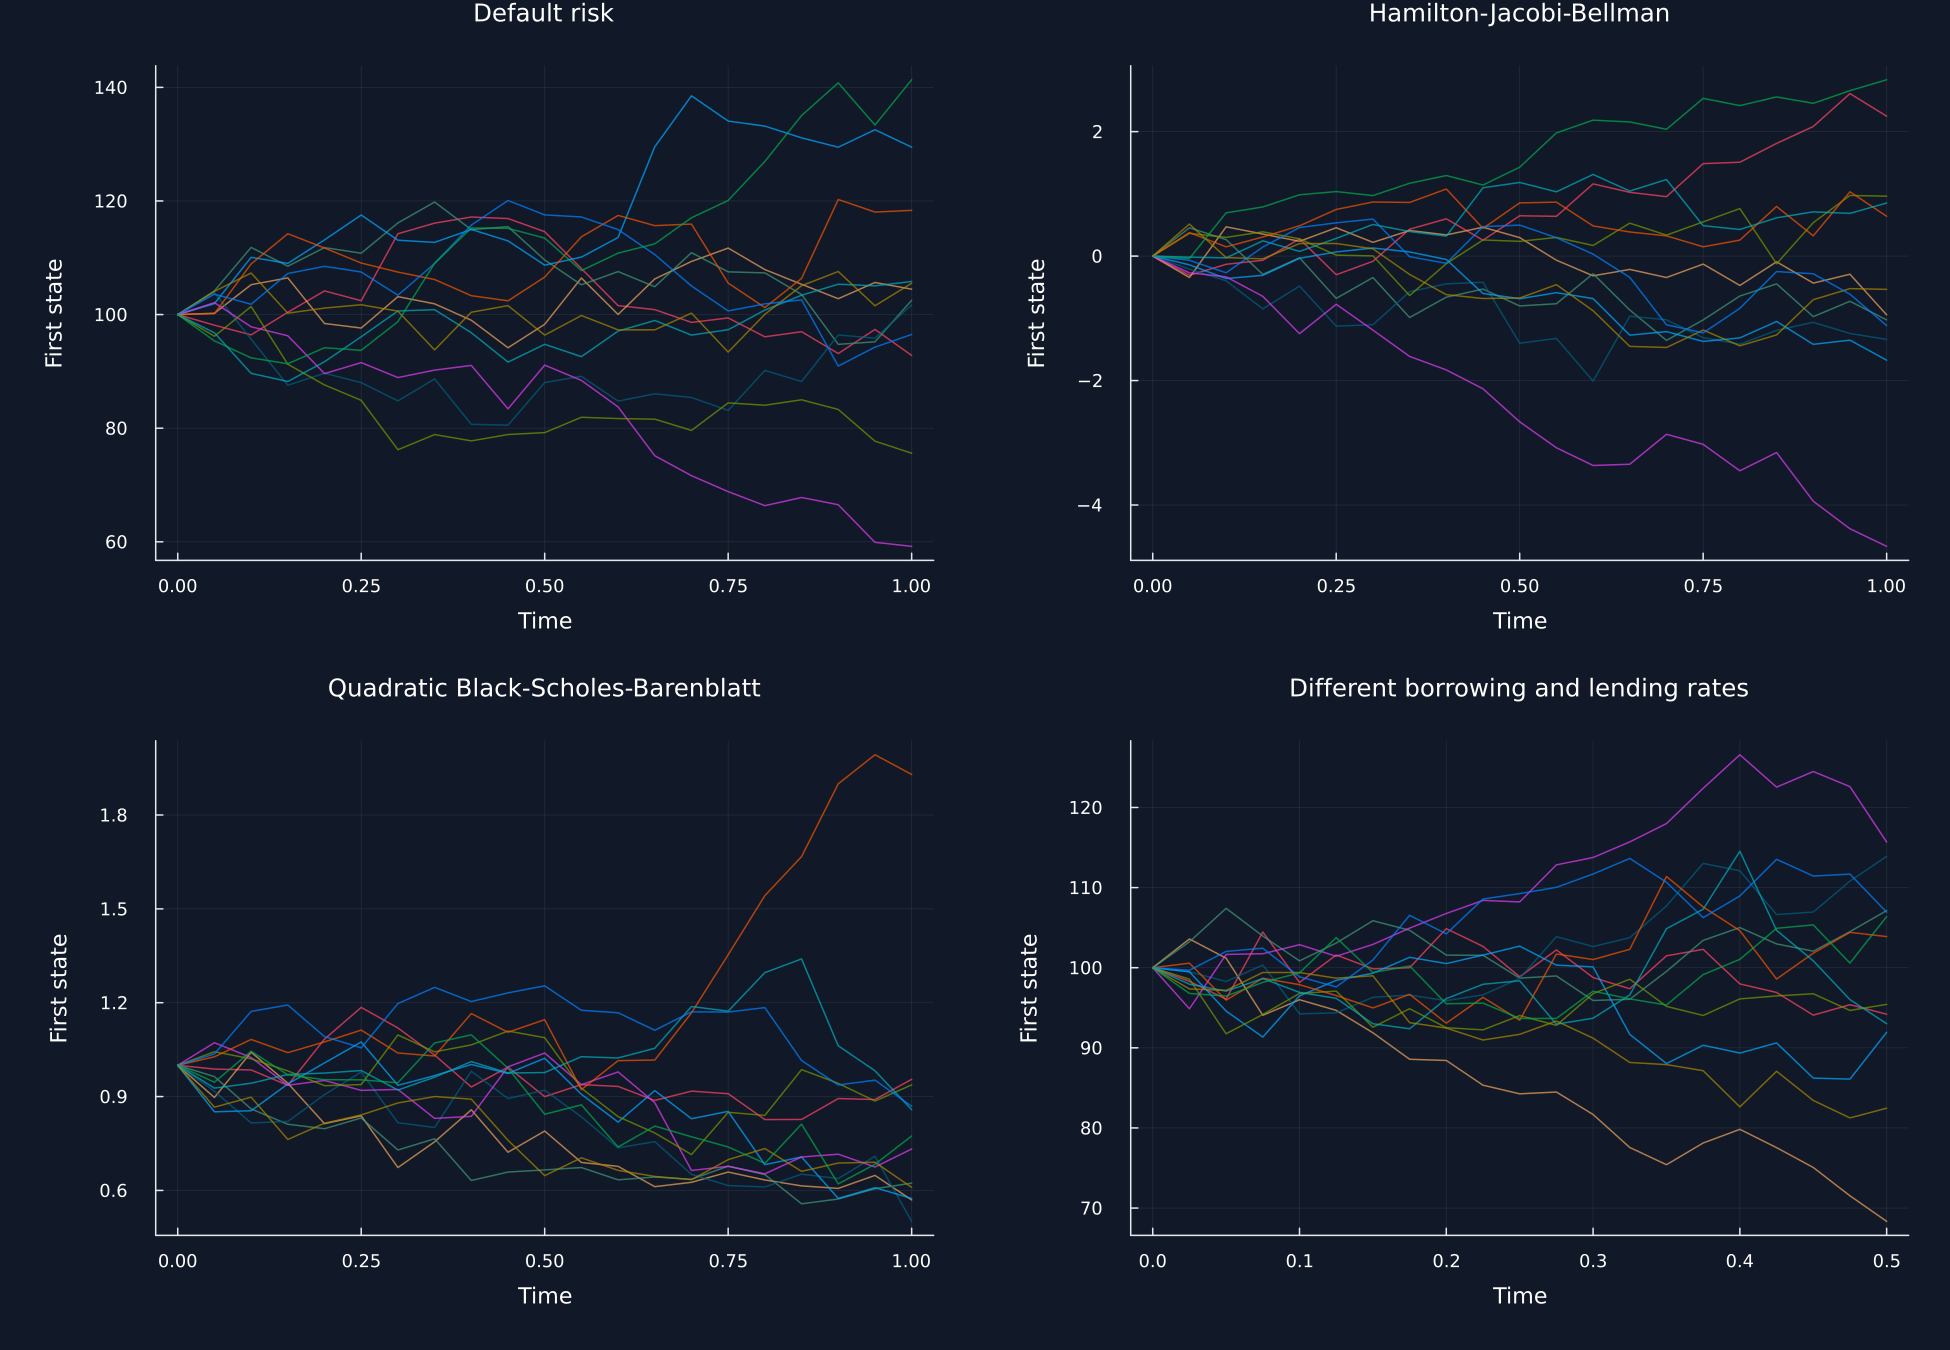

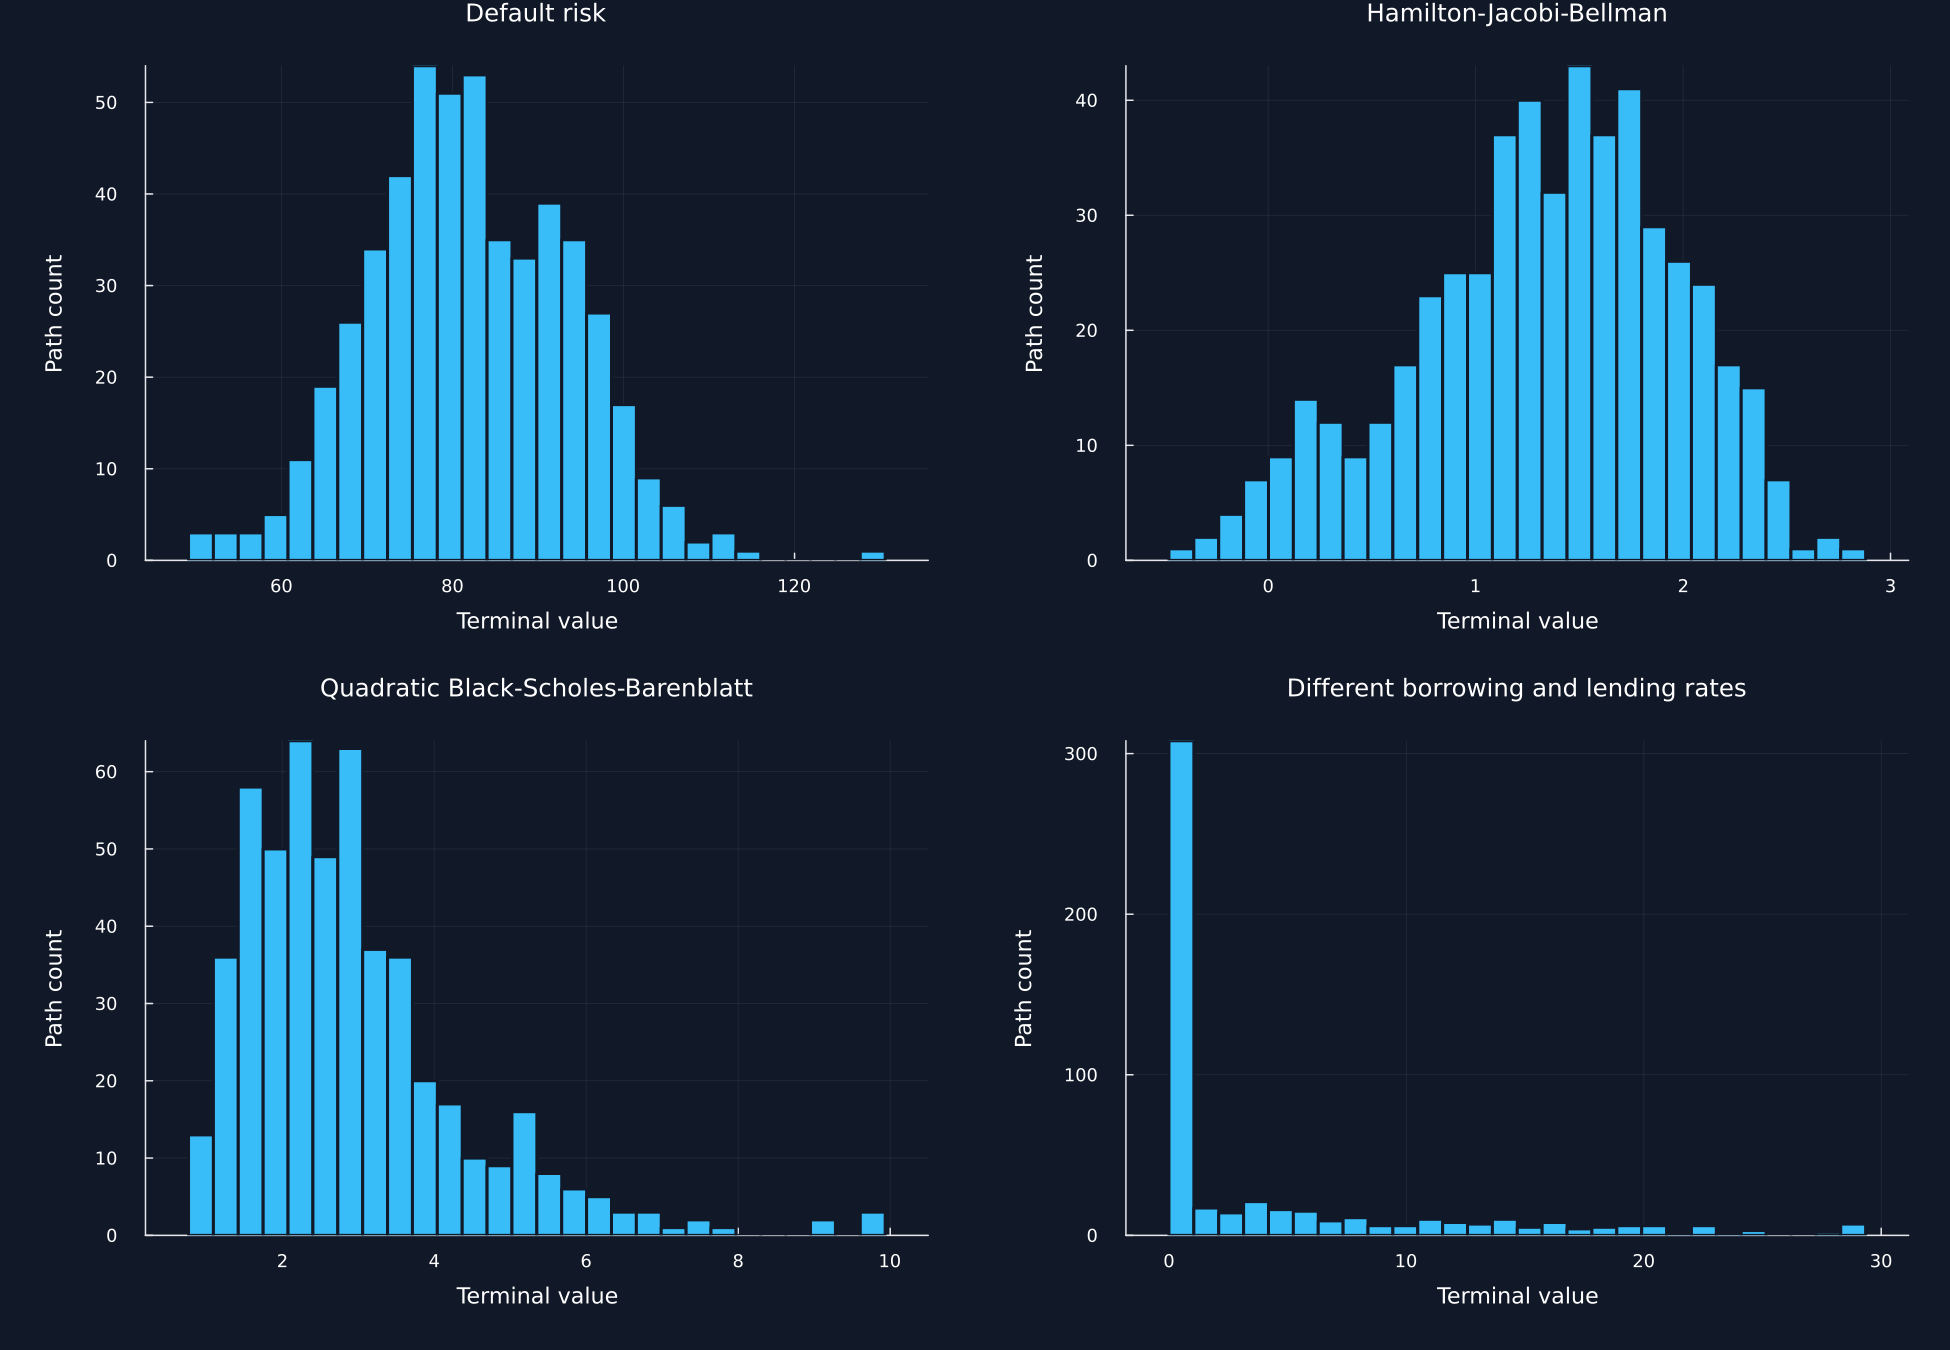

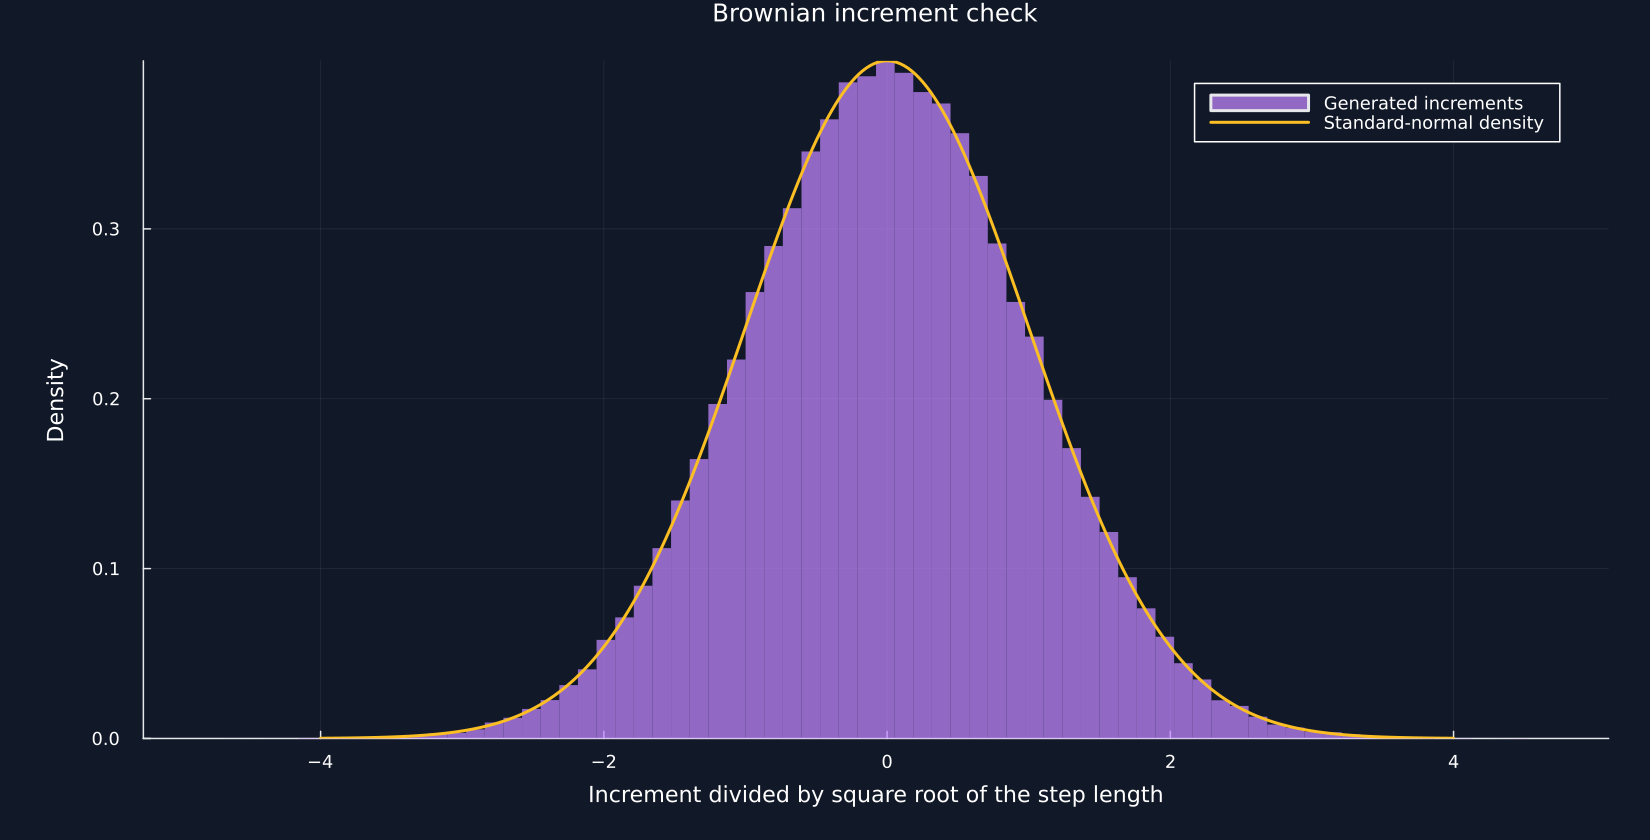

In [3]:
sampled=Dict{String,Any}(); shape_rows=NamedTuple[]; moment_rows=NamedTuple[]; terminal_rows=NamedTuple[]
for (index,(name,eq)) in enumerate(equations)
    _,dw,states=equation_sample("forward_"*families[index])
    sampled[name]=(dw,states)
    normalized=vec(permutedims(dw,(3,2,1)))./eq.sqrt_delta_t
    payoff=vec(E.terminal(eq,Float32.(states[:,:,end])))
    push!(shape_rows,(name=name,count=size(dw,1),dimension=size(dw,2),steps=size(dw,3),times=size(states,3)))
    push!(moment_rows,(name=name,center=mean(normalized),variance=var(normalized),correlation=cor(normalized[1:end-1],normalized[2:end])))
    push!(terminal_rows,(name=name,center=Float64(E.numpy_mean(payoff)),spread=Float64(E.numpy_std(payoff)),low=Float64(minimum(payoff)),high=Float64(maximum(payoff))))
end
shape_table=DataFrame(shape_rows);rename!(shape_table,["Equation","Increment paths","Dimension","Time intervals","State times"])
moment_table=DataFrame(moment_rows);rename!(moment_table,["Equation","Standardized increment mean","Standardized increment variance","Lag-one correlation"])
terminal_table=DataFrame(terminal_rows);rename!(terminal_table,["Equation","Terminal payoff mean","Terminal payoff standard deviation","Terminal payoff minimum","Terminal payoff maximum"])
table(shape_table,"forward_path_shapes","Shapes of the newly generated increments and state paths.")
table(moment_table,"brownian_moments","Sample checks for standardized Brownian increments.")
table(terminal_table,"terminal_payoff_diagnostics","Terminal-value summaries from newly generated model paths.")
panels=Plots.Plot[]
for (name,eq) in equations
    dw,states=sampled[name]; times=collect(range(0,eq.total_time;length=eq.num_time_interval+1))
    panel=plot(;title=name,xlabel="Time",ylabel="First state",legend=false)
    for row in 1:12;plot!(panel,times,states[row,1,:];linewidth=1,alpha=.72);end
    push!(panels,panel)
    save_data(DataFrame(hcat(times,permutedims(states[1:12,1,:])),vcat(["Time"],["Path "*string(i) for i in 1:12])),paths,"forward_paths_"*replace(lowercase(name),r"[^a-z]+"=>"_"))
end
save_figure(plot(panels...;layout=(2,2),size=(1300,900)),paths,"forward_model_paths")
panels=Plots.Plot[]
for (name,eq) in equations
    payoff=vec(E.terminal(eq,Float32.(sampled[name][2][:,:,end])))
    histogram_spec=histogram_data(payoff,28)
    push!(panels,bar(histogram_spec.centers,histogram_spec.values;bar_width=histogram_spec.widths,color=palette.cyan,linecolor=palette.background,legend=false,title=name,xlabel="Terminal value",ylabel="Path count"))
end
save_figure(plot(panels...;layout=(2,2),size=(1300,900)),paths,"terminal_payoff_distributions")
standardized=vcat([vec(permutedims(sampled[name][1],(3,2,1)))./eq.sqrt_delta_t for (name,eq) in equations]...)
histogram_spec=histogram_data(standardized,70;density=true)
figure=bar(histogram_spec.centers,histogram_spec.values;bar_width=histogram_spec.widths,color="#C084FC",alpha=.74,linealpha=0,label="Generated increments",xlabel="Increment divided by square root of the step length",ylabel="Density",title="Brownian increment check",size=(1100,560))
grid=collect(range(-4.0,4.0;length=300));plot!(figure,grid,exp.(-0.5.*grid.^2)./sqrt(2pi);color=palette.amber,label="Standard-normal density")
save_figure(figure,paths,"brownian_increment_distribution")


## Euler-Maruyama Time Steps

The Euler-Maruyama update on a grid $t_n=n\Delta t$ is:

$$
X_{n+1}=X_n+\mu(t_n,X_n)\Delta t+\sigma(t_n,X_n)\Delta W_n,
\qquad \Delta W_n\sim\mathcal N(0,\Delta t\,I_d).
$$

Here, $n$ labels the time interval; $\Delta t=T/N$ is the step length; $N$ is the number of intervals; $I_d$ is the $d$-dimensional identity matrix; $\Delta W_n$ is the Brownian increment; and $X_n$ approximates the state at $t_n$.

Row,Time intervals,Step length,Root mean squared state error,Maximum absolute state error
,Int64,Float64,Float64,Float64
1,5,0.2,0.0433077,1.27604
2,10,0.1,0.0302377,0.488694
3,20,0.05,0.0218287,0.394155
4,40,0.025,0.015324,0.172143
5,80,0.0125,0.0110083,0.107421


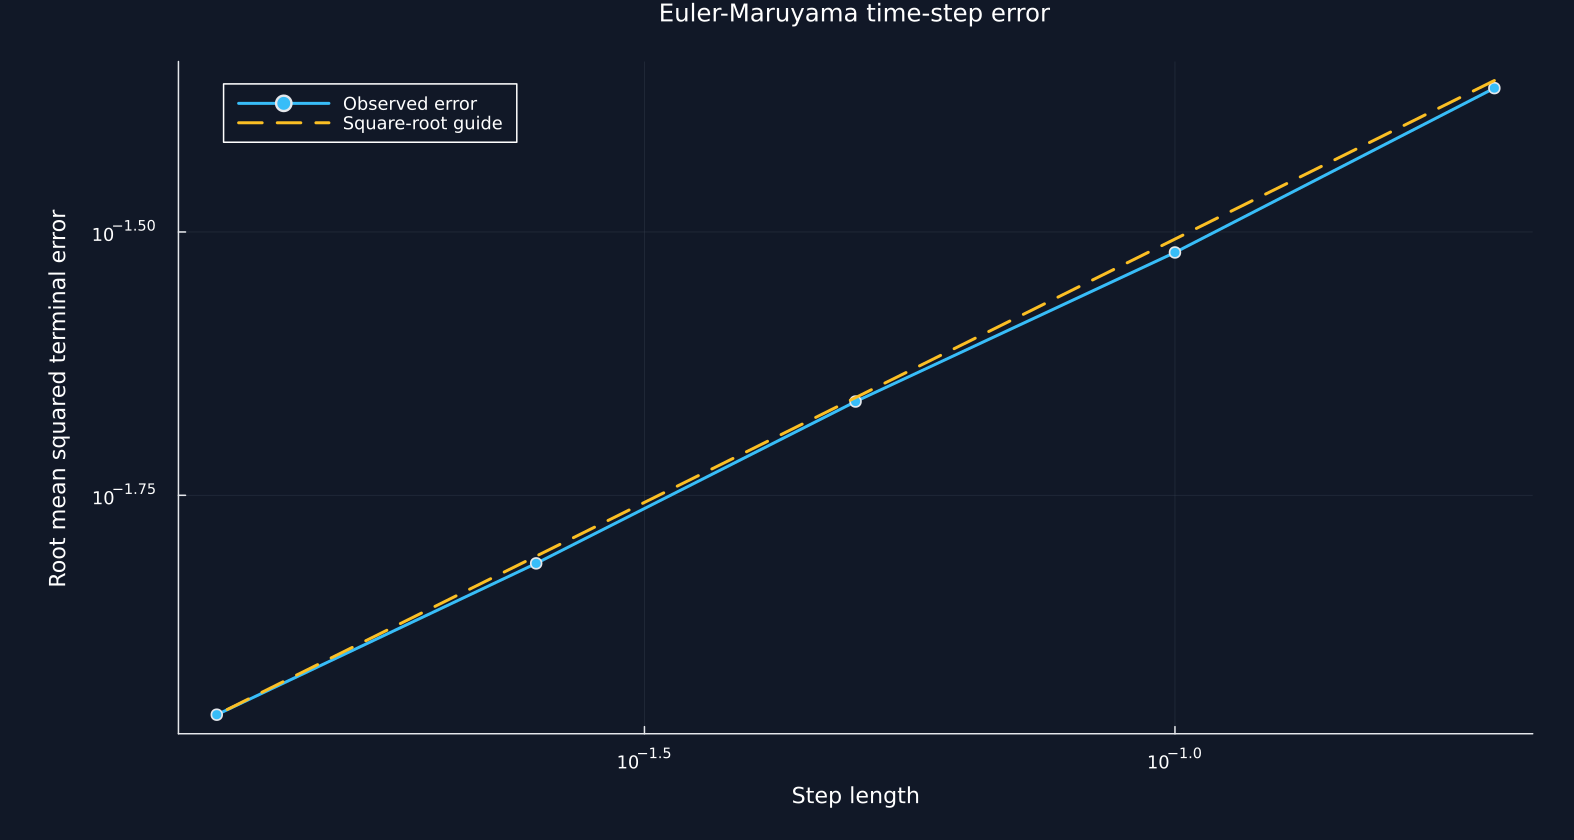

In [4]:
euler_rows=NamedTuple[]
for steps in (5,10,20,40,80)
    eq,dw,states=equation_sample("euler_"*string(steps))
    exact=eq.x_init'.*exp.(-0.5eq.sigma^2*eq.total_time .+ eq.sigma.*dropdims(sum(dw;dims=3);dims=3))
    error=states[:,:,end]-exact
    push!(euler_rows,(steps=steps,dt=eq.delta_t,rmse=sqrt(mean(abs2,error)),maximum=maximum(abs,error)))
end
euler_table=DataFrame(euler_rows);rename!(euler_table,["Time intervals","Step length","Root mean squared state error","Maximum absolute state error"])
table(euler_table,"euler_time_step_error","Euler-Maruyama error against the exact fixed-volatility update.")
figure=plot(euler_table[!,"Step length"],euler_table[!,"Root mean squared state error"];xscale=:log10,yscale=:log10,marker=:circle,color=palette.cyan,label="Observed error",xlabel="Step length",ylabel="Root mean squared terminal error",title="Euler-Maruyama time-step error",size=(1050,560))
guide=euler_table[end,"Root mean squared state error"].*sqrt.(euler_table[!,"Step length"]./euler_table[end,"Step length"])
plot!(figure,euler_table[!,"Step length"],guide;color=palette.amber,linestyle=:dash,label="Square-root guide")
save_figure(figure,paths,"euler_time_step_convergence")


## Linking backward values to terminal payoffs

The backward process associated with the equation is:

$$
dY_t=-f(t,X_t,Y_t,Z_t)\,dt+Z_t^{\mathsf T}dW_t,
\qquad Y_T=g(X_T),
\qquad Y_t=u(t,X_t).
$$

Here, $Y_t$ is the value process; $Z_t$ is the Brownian exposure or control; $f$ is the driver; $g(X_T)$ is the terminal value; and $u(t,X_t)$ links the backward value to the partial differential equation when the required regularity and integrability conditions hold.

In [5]:
generator_rows=NamedTuple[];helper_rows=NamedTuple[]
for (index,(name,eq)) in enumerate(equations)
    _,dw,states=equation_sample("generator_"*families[index])
    state=Float32.(states[:,:,4]);value=fill(1.25f0,64,1);control=control_input(families[index])
    rate=E.driver(eq,state,value,control);hamiltonian=E.hamiltonian(eq,state,value,control)
    terminal_state=Float32.(states[:,:,end]);direct=vec(E.terminal(eq,terminal_state));helper=vec(E.terminal_for_sample(eq,terminal_state))
    agree=all(isapprox.(direct,helper;rtol=1e-6,atol=1e-6))
    push!(generator_rows,(name=name,rate=Float64(A._training_mean(rate)),hamiltonian=Float64(A._training_mean(hamiltonian)),rate_finite=all(isfinite,rate),hamiltonian_finite=all(isfinite,hamiltonian)))
    push!(helper_rows,(name=name,direct=length(direct),helper=length(helper),agree=agree,gap=Float64(maximum(abs.(direct-helper)))))
end
generator_table=DataFrame(generator_rows);rename!(generator_table,["Equation","Rate mean","Hamiltonian mean","Rate finite","Hamiltonian finite"])
helper_table=DataFrame(helper_rows);rename!(helper_table,["Equation","Direct terminal values","Helper terminal values","Values agree","Maximum absolute difference"])
table(generator_table,"generator_function_checks","Finite-value checks for the released rate and Hamiltonian functions.")
table(helper_table,"terminal_helper_checks","Direct and multi-sample terminal-value comparison.")


Row,Equation,Rate mean,Hamiltonian mean,Rate finite,Hamiltonian finite
,String,Float64,Float64,String,String
1,Default risk,0.0866667,0.0,Yes,Yes
2,Hamilton-Jacobi-Bellman,0.0,0.0151176,Yes,Yes
3,Quadratic Black-Scholes-Barenblatt,0.05,2.32831e-10,Yes,Yes
4,Different borrowing and lending rates,0.0459375,-0.0125735,Yes,Yes


Row,Equation,Direct terminal values,Helper terminal values,Values agree,Maximum absolute difference
,String,Int64,Int64,String,Float64
1,Default risk,64,64,Yes,0.0
2,Hamilton-Jacobi-Bellman,64,64,Yes,0.0
3,Quadratic Black-Scholes-Barenblatt,64,64,Yes,0.0
4,Different borrowing and lending rates,64,64,No,30.1134


## Tests

In [6]:
@assert nrow(public_table)==21
@assert unique(parameter_table.Dimension)==[4]
@assert all(size(sampled[name][1])==(512,4,20)&&size(sampled[name][2])==(512,4,21) for (name,_) in equations)
@assert maximum(abs,moment_table[!,"Standardized increment mean"])<.03
@assert maximum(abs,moment_table[!,"Standardized increment variance"].-1)<.04
@assert euler_table[end,"Root mean squared state error"]<euler_table[1,"Root mean squared state error"]
@assert all(generator_table[!,"Rate finite"])&&all(generator_table[!,"Hamiltonian finite"])
@assert !helper_table[4,"Values agree"]&&all(helper_table[1:3,"Values agree"])
display(DataFrame(Test=["Public surface","Path shapes","Brownian moments","Euler refinement","Finite generators","Terminal helper mismatch exposed"],Passed=trues(6)))


Row,Test,Passed
,String,Bool
1,Public surface,true
2,Path shapes,true
3,Brownian moments,true
4,Euler refinement,true
5,Finite generators,true
6,Terminal helper mismatch exposed,true
